<h1 align="center">Macao Gross Gaming Revenue and Inbound Visitor Arrivals</h1>
<p align="center">CISC7204 Data Science and Data Visualization &mdash; Assignment 02<br>
MC653633 Huang Yudan &amp; MC655401 Chen Yuhan</p>

> **Revision note (this version).** The panel is extended from **48 to 84 monthly observations**
> (2019-01 to 2025-12) using the same official sources (DICJ revenue, MGTO arrivals), and every step
> of the original notebook is re-run on the longer panel. The key result is honest and simple:
> pooling all 84 months makes every model **worse** out-of-sample (test R-squared falls to −0.609),
> because the sample mixes three different regimes (pre-COVID, pandemic, reopening). The revised
> model keeps the **same simple form** (arrivals + trend + month dummies) but the training-window
> length is selected on **2024 validation data only**; the 2025 test months are never used for
> selection. The selected window is **24 months**, and the 2025 test R-squared is **0.658**
> (RMSE 942, MAE 833): essentially the same R² as the original 48-month Model 4 (0.666 / 929 / 755),
> though its RMSE and MAE are slightly worse.
>
> **How to read this notebook.** Start with the [Reader's guide](#readers-guide), then follow the
> modules in order. A separate `READABILITY_STATEMENT.md` gives the file map, data provenance and
> reproducibility checklist.

## What changed in this revision

| Item | Original 48-month notebook | This 84-month revision |
|---|---|---|
| Monthly observations | 48 (2022-01..2025-12) | **84 (2019-01..2025-12)** |
| Raw files | 3 | **same 3 files, extended back to 2019** |
| New external data | none | **none** (official sources only) |
| Baseline models | Models 1-3 (48m) | **re-estimated on the full 84-month pool** |
| Revised model | Model 4: regime-aware (post2023 interaction) | **same simple form** (arrivals + trend + month dummies), with the window **selected on 2024 validation data** |
| Window selection | not applicable | **2024 validation only** (2025 test untouched); 7 candidate lengths |
| Why | baseline out-of-sample R² ≈ 0 | all 84 months pooled: out-of-sample R² is **negative** (structural breaks at 2020-02 and 2023-01) |
| Evaluation | naive mean, seasonal naive, last value | same benchmarks + **rolling one-step backtest (2024-2025)** |
| Conclusion | "Model 4 is a usable first draft" | pooling fails; **24m validation-selected window** gives R² = 0.658, essentially equal R² to the original 48m version (but slightly worse RMSE/MAE) |

The 84-month extension is not wasted: it is exactly what exposes the regime problem. The revised
model is deliberately simple (a window choice, no new variables), so it stays easy to explain and
defend. Crucially, the 24-month length is chosen on **2024** validation data; the 2025 test is used
only once, after the window is fixed.

<a id="readers-guide"></a>
## Reader's guide (read this first)

This notebook is written to be read top-to-bottom. Each module has one job:

| Section | Question it answers | Main output |
|---|---|---|
| Module 2 | Is the 84-month panel complete, official and consistent? | validation table, data dictionary |
| Module 3 | What do the three regimes look like? | Figures 1-4 |
| Modules 4-5 | Why do the pooled 84-month models fail? | baseline metrics, Chow tests |
| Module 6 | What candidate model and window are proposed? | 24m candidate |
| Module 7 | Is the window selected without touching 2025? | 2024 validation table, rolling backtest |
| Module 8 | Is the selected model better than alternatives? | comparison table, Figures 5-8 |
| Findings | What can and cannot be claimed? | limitations and references |

**Key terms**

- **GGR**: gross gaming revenue, million MOP. **Arrivals**: inbound visitor arrivals, 10,000 persons.
- **Regime**: `pre_covid` (2019-01..2020-01), `pandemic` (2020-02..2022-12), `reopening` (2023-01..2025-12).
- **Test window**: the last 10 months, 2025-03..2025-12. It is used once, after the window is selected.
- **Validation window**: 2024-01..2024-12. Only this window is used to choose the training-window length.
- **Naive mean / seasonal naive / last value**: benchmarks that predict the training mean, the same month one year earlier, or the previous month.
- **R² can be negative.** A negative test R² means the model is worse than always predicting the test-period mean; it is not a bug.
- **RMSE / MAE**: error in million MOP; lower is better. MAE is less sensitive to one large miss than RMSE.

**Reading rule:** all numbers in the text are produced by the code cells below. If you change a cell,
use `Restart & Run All` before comparing numbers. The file `READABILITY_STATEMENT.md` in the project
folder gives the file map, data provenance and a reproducibility checklist.

## Contents

- [Reader's guide](#readers-guide)
- [Instructions](#instructions)
- [About the dataset](#about-the-dataset)
- [Data dictionary](#data-dictionary)
- [Module 0: Setup](#module-0-setup)
- [Module 1: Importing the datasets](#module-1-importing-the-datasets)
- [Module 2: Data wrangling and validation](#module-2-data-wrangling-and-validation)
- [Module 3: Exploratory data analysis](#module-3-exploratory-data-analysis)
- [Module 4: Baseline models (Models 1-3)](#module-4-baseline-models)
- [Module 5: Why the pooled 84-month baselines fail](#module-5-why-the-pooled-84-month-baselines-fail)
- [Module 6: Candidate model - 24-month window](#module-6-revised-model)
- [Module 7: Validation-based window selection and rolling backtest](#module-7-validation)
- [Module 8: Comparison and diagnostics](#module-8-comparison)
- [Findings, limitations and references](#findings-limitations-and-references)

<a id="instructions"></a>
## Instructions

Run the notebook from top to bottom (`Restart & Run All`). It expects three raw files under
`data/raw/` (next to the notebook):

- `income_2019_2025.csv` &mdash; DICJ monthly gross gaming revenue, 2019-01 to 2025-12
- `visitors_total_2019_2025.csv` &mdash; MGTO total inbound arrivals, 2019-01 to 2025-12
- `visitors_by_market_2019_2025.csv` &mdash; MGTO arrivals by 28 source markets, 2019-01 to 2025-12

All figures are written to `figures/`; the cleaned 84-month panel is written to
`gambling_visitors_cleaned.csv`. A pre-built copy of the panel is also available at
`data/processed/panel_84m.csv`.

<a id="about-the-dataset"></a>
## About the dataset

Three official monthly series published by the Government of the Macao Special Administrative Region,
now covering **84 consecutive months (2019-01 to 2025-12)**:

| Dataset | Provider | Coverage |
|---|---|---|
| Gross gaming revenue, monthly (million MOP) | Gaming Inspection and Coordination Bureau (DICJ) | Jan 2019 - Dec 2025 |
| Total inbound visitor arrivals | MGTO, Macao Tourism Data+ | Jan 2019 - Dec 2025 |
| Inbound arrivals by source market (28 markets) | MGTO, Macao Tourism Data+ | Jan 2019 - Dec 2025 |

The 2019-2021 segment is new in this version: it was fetched directly from the official DICJ XML
statistics page and the MGTO Tourism Data+ platform, then checked digit-by-digit against the official
DSEC figures (2019 arrivals 39,406,181; 2020 arrivals 5,896,848; 2021 arrivals 7,705,943; 2019 GGR
cumulative 292,455 and 2020 GGR cumulative 60,441 million MOP). Revenue is published in million
patacas; visitor counts are rescaled to units of 10,000 persons so that regression coefficients read
as *million MOP per 10,000 additional visitors*.

<a id="data-dictionary"></a>
## Data dictionary

| Variable | Definition | Unit | Source |
|---|---|---|---|
| `date` | First day of the reference month | YYYY-MM-DD | derived |
| `year`, `month` | Calendar year and month of `date` | integer | derived |
| `ggr_million_mop` | Monthly gross gaming revenue (target) | million MOP | DICJ |
| `ggr_yoy_change` | Year-on-year change of revenue as a ratio (1.0 = +100%). 2023 values are very large because they compare with the pandemic trough; documented but not used as a regressor | ratio | DICJ |
| `total_visitors` | Monthly inbound visitor arrivals, all markets | persons | MGTO Data+ |
| `mainland_visitors` | Arrivals from Mainland China | persons | MGTO Data+ |
| `hongkong_visitors` | Arrivals from the Hong Kong SAR | persons | MGTO Data+ |
| `other_visitors` | Arrivals from Taiwan region and all international markets | persons | MGTO Data+ |
| `*_visitors_10k` | The three visitor series divided by 10,000 | 10,000 persons | derived |
| `mainland_ratio`, `hongkong_ratio`, `other_ratio` | Source-market share of total arrivals | proportion | derived |
| `t` | Month index 1-84; a deterministic linear trend | index | derived |
| `post2023` | 1 from 2023-01 onward (post-reopening regime), else 0 | 0/1 | derived |
| `total_post` | `total_visitors_10k × post2023`; regime-specific slope | interaction | derived |
| `m_2` ... `m_12` | Calendar-month dummies (January is the baseline) | 0/1 | derived |
| `regime` | Regime label: `pre_covid` / `pandemic` / `reopening` | label | derived |

<a id="module-0-setup"></a>
## Module 0: Setup

Libraries, plotting defaults and output folders. Relative paths make the notebook portable.

In [1]:
import os
from pathlib import Path

# keep Matplotlib/Fontconfig caches inside the project (avoids permission warnings)
BASE_DIR = Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(BASE_DIR / ".mplconfig"))
os.environ.setdefault("XDG_CACHE_HOME", str(BASE_DIR / ".cache"))

import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from matplotlib.ticker import MaxNLocator, StrMethodFormatter
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

%matplotlib inline

FIG_DIR = BASE_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "SimHei", "Heiti TC", "PingFang SC", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["savefig.bbox"] = "tight"
sns.set_theme(style="whitegrid", rc={"figure.dpi": 110})

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 50)

print("python :", sys.version.split()[0])
print("pandas :", pd.__version__)
print("numpy  :", np.__version__)
print("sklearn:", sklearn.__version__)

Matplotlib is building the font cache; this may take a moment.


python : 3.14.6
pandas : 3.0.5
numpy  : 2.5.2
sklearn: 1.9.0


<a id="module-1-importing-the-datasets"></a>
## Module 1: Importing the datasets

The three source files are the same shape as the original notebook, now covering 2019-01 to 2025-12.

In [2]:
RAW = BASE_DIR / "data" / "raw"
income_raw = pd.read_csv(RAW / "income_2019_2025.csv", encoding="utf-8-sig")
total_raw = pd.read_csv(RAW / "visitors_total_2019_2025.csv", encoding="utf-8-sig")
place_raw = pd.read_csv(RAW / "visitors_by_market_2019_2025.csv", encoding="utf-8-sig")

for name, frame in [("income_raw", income_raw), ("total_raw", total_raw), ("place_raw", place_raw)]:
    print(f"{name:<10} {frame.shape[0]:>3} rows x {frame.shape[1]} columns   {list(frame.columns)}")

income_raw  84 rows x 4 columns   ['年份', '月份', '毛收入(百万澳门元)', '同比变动率']
total_raw   84 rows x 8 columns   ['年', '季', '月', '客源市場', '總入境旅客人次', '備註', '總入境旅客增長率', '備註.1']
place_raw  2352 rows x 8 columns   ['年', '季', '月', '客源市場', '總入境旅客人次', '備註', '總入境旅客增長率', '備註.1']


In [3]:
income_raw.head()

,年份,月份,毛收入(百万澳门元),同比变动率
0,2019年,一月份,24942,-0.050
1,2019年,二月份,25370,0.044
2,2019年,三月份,25840,-0.004
3,2019年,四月份,23588,-0.083
4,2019年,五月份,25952,0.018


In [4]:
total_raw.head()

,年,季,月,客源市場,總入境旅客人次,備註,總入境旅客增長率,備註.1
0,2019,NaN,1,總數,3425126,NaN,24.9,NaN
1,2019,NaN,2,總數,3545701,NaN,15.5,NaN
2,2019,NaN,3,總數,3388931,NaN,24.0,NaN
3,2019,NaN,4,總數,3432187,NaN,15.9,NaN
4,2019,NaN,5,總數,3396835,NaN,25.6,NaN


In [5]:
place_raw.head()

,年,季,月,客源市場,總入境旅客人次,備註,總入境旅客增長率,備註.1
0,2019,NaN,1,澳洲,11020,NaN,11.0,NaN
1,2019,NaN,2,澳洲,5252,NaN,5.7,NaN
2,2019,NaN,3,澳洲,7693,NaN,4.6,NaN
3,2019,NaN,4,澳洲,10991,NaN,9.9,NaN
4,2019,NaN,5,澳洲,7424,NaN,11.4,NaN


<a id="module-2-data-wrangling-and-validation"></a>
## Module 2: Data wrangling and validation

1. Normalise revenue labels to numeric year/month.
2. Collapse the 28 source markets into three groups (Mainland, Hong Kong SAR, other).
3. Merge revenue with arrivals on calendar month.
4. Rescale visitors to 10,000-person units and compute source-market shares.
5. Run the same validation battery as the original notebook, plus official-total checks for the
   extended 2019-2021 segment.
6. Persist the cleaned 84-month panel.

In [6]:
MONTH_MAP = {
    "一月份": 1, "二月份": 2, "三月份": 3, "四月份": 4, "五月份": 5, "六月份": 6,
    "七月份": 7, "八月份": 8, "九月份": 9, "十月份": 10, "十一月份": 11, "十二月份": 12,
}

# ---- 2.1 revenue: Chinese labels -> numeric year/month --------------------
revenue = (income_raw
           .rename(columns={
               "年份": "year_label",
               "月份": "month_label",
               "毛收入(百万澳门元)": "ggr_million_mop",
               "同比变动率": "ggr_yoy_change",
           })
           .assign(year=lambda d: d["year_label"].str.replace("年", "", regex=False).astype(int),
                   month=lambda d: d["month_label"].map(MONTH_MAP))
           .drop(columns=["year_label", "month_label"]))

assert revenue["month"].notna().all(), "unmapped Chinese month label"
revenue["date"] = pd.to_datetime(dict(year=revenue["year"], month=revenue["month"], day=1))

# ---- 2.2 visitors: 28 source markets -> 3 groups -------------------------
MARKET_GROUP = {"中國內地": "mainland_visitors", "香港特區": "hongkong_visitors"}
place = place_raw.assign(
    market=lambda d: d["客源市場"].map(MARKET_GROUP).fillna("other_visitors"),
    visitors=lambda d: d["總入境旅客人次"],
)

by_market = (place.groupby(["年", "月", "market"])["visitors"].sum()
             .unstack("market").reset_index())

total_monthly = (total_raw.loc[total_raw["客源市場"] == "總數", ["年", "月", "總入境旅客人次"]]
                 .rename(columns={"總入境旅客人次": "total_visitors"}))

monthly = total_monthly.merge(by_market, on=["年", "月"], how="inner", validate="one_to_one")
monthly["date"] = pd.to_datetime(dict(year=monthly["年"], month=monthly["月"], day=1))

# ---- 2.3 merge revenue with visitors ------------------------------------
df = (revenue.merge(monthly.drop(columns=["年", "月"]), on="date", how="left", validate="one_to_one")
      .sort_values("date").reset_index(drop=True))

print(f"revenue months              : {revenue['date'].nunique()}")
print(f"visitor months              : {monthly['date'].nunique()}")
print(f"revenue months without visitor data: {int(df['total_visitors'].isna().sum())}")
print(f"columns after merge         : {list(df.columns)}")

revenue months              : 84
visitor months              : 84
revenue months without visitor data: 0
columns after merge         : ['ggr_million_mop', 'ggr_yoy_change', 'year', 'month', 'date', 'total_visitors', 'hongkong_visitors', 'mainland_visitors', 'other_visitors']


In [7]:
# ---- 2.4 units: persons -> 10,000 persons -------------------------------
for col in ["total_visitors", "mainland_visitors", "hongkong_visitors", "other_visitors"]:
    df[f"{col}_10k"] = df[col] / 10_000

# ---- 2.5 source-market shares -------------------------------------------
for market in ["mainland", "hongkong", "other"]:
    df[f"{market}_ratio"] = df[f"{market}_visitors"] / df["total_visitors"]

print(f"panel size : {len(df)} months, {df['date'].min():%Y-%m} to {df['date'].max():%Y-%m}")

panel size : 84 months, 2019-01 to 2025-12


In [8]:
# ---- 2.6 derived columns: trend, regime, interactions, month dummies ----
df["t"] = np.arange(1, len(df) + 1)
df["post2023"] = (df["date"] >= pd.Timestamp("2023-01-01")).astype(int)
df["total_post"] = df["total_visitors_10k"] * df["post2023"]

df["regime"] = "reopening"
df.loc[df["date"] < pd.Timestamp("2020-02-01"), "regime"] = "pre_covid"
df.loc[(df["date"] >= pd.Timestamp("2020-02-01"))
       & (df["date"] < pd.Timestamp("2023-01-01")), "regime"] = "pandemic"

for m in range(2, 13):
    df[f"m_{m}"] = (df["month"] == m).astype(int)

print("regime counts:")
print(df["regime"].value_counts().to_string())
print("derived columns present:",
      [c for c in ["t", "post2023", "total_post", "regime"] + [f"m_{m}" for m in range(2, 13)]
       if c in df.columns])

regime counts:
regime
reopening    36
pandemic     35
pre_covid    13
derived columns present: ['t', 'post2023', 'total_post', 'regime', 'm_2', 'm_3', 'm_4', 'm_5', 'm_6', 'm_7', 'm_8', 'm_9', 'm_10', 'm_11', 'm_12']


In [9]:
# ---- 2.7 validation checks ----------------------------------------------
expected_months = pd.date_range(df["date"].min(), df["date"].max(), freq="MS")
market_sum = df[["mainland_visitors", "hongkong_visitors", "other_visitors"]].sum(axis=1)
ratio_sum = df[["mainland_ratio", "hongkong_ratio", "other_ratio"]].sum(axis=1)

checks = pd.DataFrame([
    ("duplicate month keys", float(df["date"].duplicated().sum()), 0),
    ("missing calendar months", float(len(expected_months.difference(pd.DatetimeIndex(df["date"])))), 0),
    ("non-positive revenue values", float((df["ggr_million_mop"] <= 0).sum()), 0),
    ("negative visitor values", float((df[["total_visitors", "mainland_visitors",
                                           "hongkong_visitors", "other_visitors"]] < 0).sum().sum()), 0),
    ("max |market sum - total| (persons)", float((market_sum - df["total_visitors"]).abs().max()), 0.5),
    ("max |share sum - 1|", float((ratio_sum - 1).abs().max()), 1e-6),
    ("2019 arrivals vs official DSEC (39,406,181)", float(abs(df.loc[df["year"] == 2019, "total_visitors"].sum() - 39406181)), 1),
    ("2020 arrivals vs official DSEC (5,896,848)", float(abs(df.loc[df["year"] == 2020, "total_visitors"].sum() - 5896848)), 1),
    ("2021 arrivals vs official DSEC (7,705,943)", float(abs(df.loc[df["year"] == 2021, "total_visitors"].sum() - 7705943)), 1),
    ("2019 GGR cumulative vs official DICJ (292,455)", float(abs(df.loc[df["year"] == 2019, "ggr_million_mop"].sum() - 292455)), 1),
    ("2020 GGR cumulative vs official DICJ (60,441)", float(abs(df.loc[df["year"] == 2020, "ggr_million_mop"].sum() - 60441)), 1),
], columns=["check", "value", "tolerance"])
checks["status"] = np.where(checks["value"] <= checks["tolerance"], "pass", "FAIL")
checks["value"] = checks["value"].map(lambda v: f"{v:.6g}")
checks[["check", "value", "status"]]

,check,value,status
0,duplicate month keys,0,pass
1,missing calendar months,0,pass
2,non-positive revenue values,0,pass
3,negative visitor values,0,pass
4,max |market sum - total| (persons),0,pass
5,max |share sum - 1|,1.11022e-16,pass
6,"2019 arrivals vs official DSEC (39,406,181)",0,pass
7,"2020 arrivals vs official DSEC (5,896,848)",0,pass
8,"2021 arrivals vs official DSEC (7,705,943)",0,pass
9,"2019 GGR cumulative vs official DICJ (292,455)",1,pass


In [10]:
df.head()

,ggr_million_mop,ggr_yoy_change,year,month,date,total_visitors,hongkong_visitors,mainland_visitors,other_visitors,total_visitors_10k,mainland_visitors_10k,hongkong_visitors_10k,other_visitors_10k,mainland_ratio,hongkong_ratio,other_ratio,t,post2023,total_post,regime,m_2,m_3,m_4,m_5,m_6,m_7,m_8,m_9,m_10,m_11,m_12
0,24942,-0.050,2019,1,2019-01-01,3425126,533740,2504494,386892,342.5126,250.4494,53.3740,38.6892,0.731212,0.155831,0.112957,1,0,0.0,pre_covid,0,0,0,0,0,0,0,0,0,0,0
1,25370,0.044,2019,2,2019-02-01,3545701,658030,2559144,328527,354.5701,255.9144,65.8030,32.8527,0.721760,0.185585,0.092655,2,0,0.0,pre_covid,1,0,0,0,0,0,0,0,0,0,0
2,25840,-0.004,2019,3,2019-03-01,3388931,601344,2384653,402934,338.8931,238.4653,60.1344,40.2934,0.703659,0.177444,0.118897,3,0,0.0,pre_covid,0,1,0,0,0,0,0,0,0,0,0
3,23588,-0.083,2019,4,2019-04-01,3432187,696902,2339868,395417,343.2187,233.9868,69.6902,39.5417,0.681743,0.203049,0.115208,4,0,0.0,pre_covid,0,0,1,0,0,0,0,0,0,0,0
4,25952,0.018,2019,5,2019-05-01,3396835,581780,2425741,389314,339.6835,242.5741,58.1780,38.9314,0.714118,0.171271,0.114611,5,0,0.0,pre_covid,0,0,0,1,0,0,0,0,0,0,0


Statistical summary of the cleaned 84-month panel:

In [11]:
df[["ggr_million_mop", "total_visitors_10k", "mainland_visitors_10k",
     "hongkong_visitors_10k", "other_visitors_10k"]].describe().round(2)

,ggr_million_mop,total_visitors_10k,mainland_visitors_10k,hongkong_visitors_10k,other_visitors_10k
count,84.00,84.00,84.00,84.00,84.00
mean,13561.98,192.76,139.75,36.88,16.14
std,8179.60,131.73,91.25,28.25,14.69
min,398.00,0.98,0.73,0.03,0.02
25%,6227.75,58.16,53.09,4.88,0.63
50%,15804.00,241.45,162.10,54.37,18.22
75%,20337.75,309.36,216.89,60.99,28.54
max,26443.00,421.90,325.79,74.53,42.09


In [12]:
# ---- 2.8 persist the cleaned panel and its dictionary --------------------
data_dictionary = pd.DataFrame([
    ("date", "First day of the reference month", "YYYY-MM-DD", "derived"),
    ("year, month", "Calendar year and month of date", "integer", "derived"),
    ("ggr_million_mop", "Monthly gross gaming revenue (target variable)", "million MOP", "DICJ"),
    ("ggr_yoy_change", "Year-on-year change in revenue as a ratio (1.0 = +100%); 2023 values are extreme because the base is the pandemic trough", "ratio", "DICJ"),
    ("total_visitors", "Monthly inbound visitor arrivals, all source markets", "persons", "MGTO Data+"),
    ("mainland_visitors", "Arrivals from Mainland China", "persons", "MGTO Data+"),
    ("hongkong_visitors", "Arrivals from the Hong Kong SAR", "persons", "MGTO Data+"),
    ("other_visitors", "Arrivals from the Taiwan region and all international markets", "persons", "MGTO Data+"),
    ("total_visitors_10k", "total_visitors / 10,000", "10,000 persons", "derived"),
    ("mainland_visitors_10k", "mainland_visitors / 10,000", "10,000 persons", "derived"),
    ("hongkong_visitors_10k", "hongkong_visitors / 10,000", "10,000 persons", "derived"),
    ("other_visitors_10k", "other_visitors / 10,000", "10,000 persons", "derived"),
    ("mainland_ratio", "mainland_visitors / total_visitors", "proportion", "derived"),
    ("hongkong_ratio", "hongkong_visitors / total_visitors", "proportion", "derived"),
    ("other_ratio", "other_visitors / total_visitors", "proportion", "derived"),
    ("t", "Month index 1-84, a deterministic linear trend", "index", "derived"),
    ("post2023", "1 from 2023-01 onward (post-reopening regime), else 0", "0/1", "derived"),
    ("total_post", "total_visitors_10k x post2023 (regime-specific slope)", "interaction", "derived"),
    ("regime", "pre_covid (2019-01..2020-01) / pandemic (2020-02..2022-12) / reopening (2023-01..2025-12)", "category", "derived"),
    ("m_2 ... m_12", "Calendar-month dummies (January is the baseline)", "0/1", "derived"),
], columns=["variable", "definition", "unit", "source"])

df.to_csv(BASE_DIR / "gambling_visitors_cleaned.csv", index=False)
data_dictionary.to_csv(BASE_DIR / "data_dictionary_84m.csv", index=False)
print("saved -> gambling_visitors_cleaned.csv")
print("saved -> data_dictionary_84m.csv")

saved -> gambling_visitors_cleaned.csv
saved -> data_dictionary_84m.csv


<a id="module-3-exploratory-data-analysis"></a>
## Module 3: Exploratory data analysis

Four charts, following the original notebook, now covering all 84 months. The first chart shades the
three regimes (pre-COVID, pandemic, reopening); the seasonal and composition charts use the reopening
segment (2023-01..2025-12) so that the pandemic collapse does not distort the averages.

In [13]:
def save_figure(fig, filename):
    path = FIG_DIR / filename
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print("saved ->", path.name)
    return path

**Figure 1.** Monthly gross gaming revenue and total inbound arrivals, 2019-2025, with regime shading.

saved -> fig1_trend_84m.png


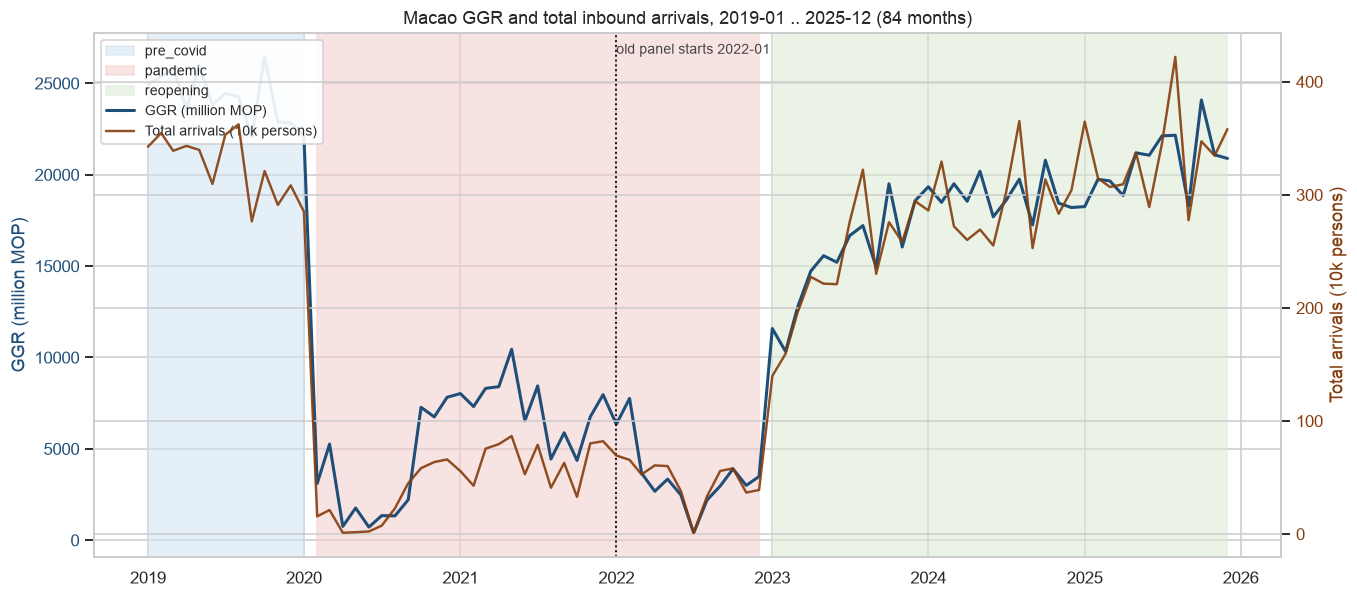

In [14]:
# ---- Figure 1: monthly trend, GGR vs total arrivals ---------------------
fig, ax1 = plt.subplots(figsize=(12.5, 5.6))

regimes = [("pre_covid", "2019-01-01", "2020-01-01", "#cfe2f3"),
           ("pandemic", "2020-02-01", "2022-12-01", "#f4cccc"),
           ("reopening", "2023-01-01", "2025-12-01", "#d9ead3")]
for label, start, end, color in regimes:
    ax1.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=color, alpha=0.55, label=label)

ax1.plot(df["date"], df["ggr_million_mop"], color="#1f4e79", linewidth=2, label="GGR (million MOP)")
ax1.set_ylabel("GGR (million MOP)", color="#1f4e79")
ax1.tick_params(axis="y", labelcolor="#1f4e79")
ax1.axvline(pd.Timestamp("2022-01-01"), color="black", linestyle=":", linewidth=1.2)
ax1.text(pd.Timestamp("2022-01-01"), ax1.get_ylim()[1] * 0.98, "old panel starts 2022-01",
         fontsize=9, color="#444444", ha="left", va="top")

ax2 = ax1.twinx()
ax2.plot(df["date"], df["total_visitors_10k"], color="#843c0c", linewidth=1.6, alpha=0.9,
         label="Total arrivals (10k persons)")
ax2.set_ylabel("Total arrivals (10k persons)", color="#843c0c")
ax2.tick_params(axis="y", labelcolor="#843c0c")

ax1.set_title("Macao GGR and total inbound arrivals, 2019-01 .. 2025-12 (84 months)")
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=9, framealpha=0.9)
fig.tight_layout()
save_figure(fig, "fig1_trend_84m.png")
plt.show()

**Figure 2.** Calendar-month profile of GGR and arrivals, reopening segment (2023-01..2025-12).

saved -> fig2_seasonal_84m.png


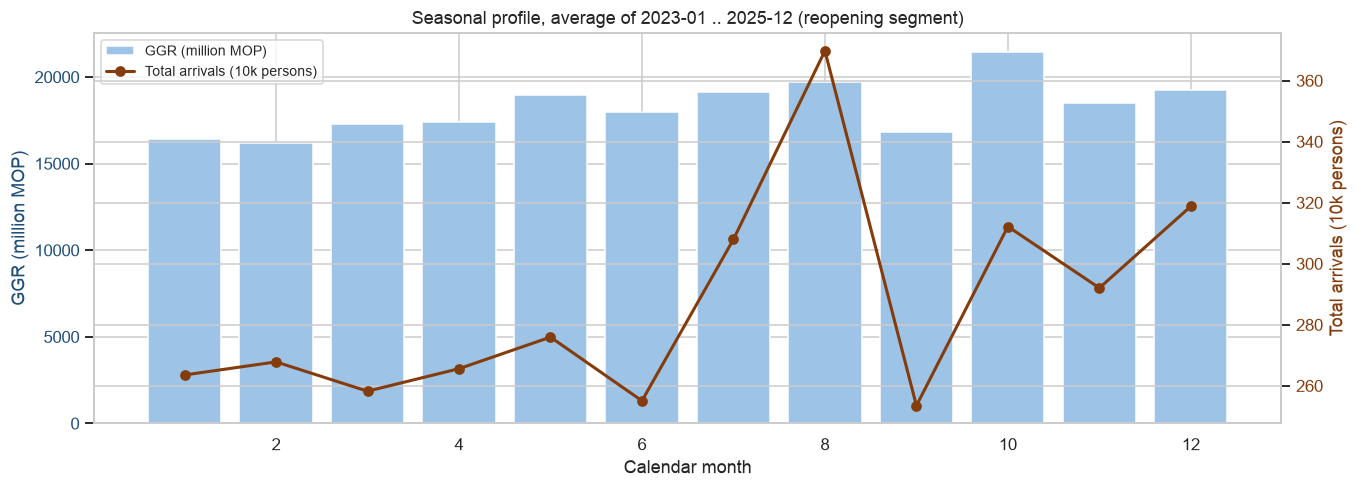

In [15]:
# ---- Figure 2: seasonal profile, reopening monthly average --------------
reop = df[df["date"] >= pd.Timestamp("2023-01-01")]
monthly_avg = reop.groupby("month")[["ggr_million_mop", "total_visitors_10k"]].mean()

fig, ax1 = plt.subplots(figsize=(12.5, 4.6))
ax1.bar(monthly_avg.index, monthly_avg["ggr_million_mop"], color="#9dc3e6", edgecolor="white",
        label="GGR (million MOP)")
ax1.set_xlabel("Calendar month")
ax1.set_ylabel("GGR (million MOP)", color="#1f4e79")
ax1.tick_params(axis="y", labelcolor="#1f4e79")
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2 = ax1.twinx()
ax2.plot(monthly_avg.index, monthly_avg["total_visitors_10k"], color="#843c0c",
         marker="o", linewidth=2, label="Total arrivals (10k persons)")
ax2.set_ylabel("Total arrivals (10k persons)", color="#843c0c")
ax2.tick_params(axis="y", labelcolor="#843c0c")

ax1.set_title("Seasonal profile, average of 2023-01 .. 2025-12 (reopening segment)")
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=9)
fig.tight_layout()
save_figure(fig, "fig2_seasonal_84m.png")
plt.show()

**Figure 3.** Average source-market structure of inbound arrivals, reopening segment (2023-01..2025-12).

saved -> fig3_market_84m.png


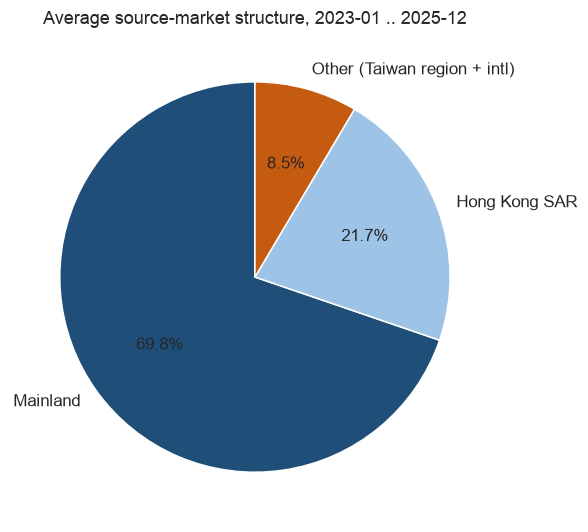

In [16]:
# ---- Figure 3: source-market composition -------------------------------
shares = reop[["mainland_ratio", "hongkong_ratio", "other_ratio"]].mean()
fig, ax = plt.subplots(figsize=(7.0, 5.0))
ax.pie(shares, labels=["Mainland", "Hong Kong SAR", "Other (Taiwan region + intl)"],
       colors=["#1f4e79", "#9dc3e6", "#c55a11"], autopct="%.1f%%", startangle=90,
       textprops={"fontsize": 11})
ax.set_title("Average source-market structure, 2023-01 .. 2025-12")
fig.tight_layout()
save_figure(fig, "fig3_market_84m.png")
plt.show()

**Figure 4.** Correlation matrix of GGR, arrivals by market and calendar month, all 84 months.

saved -> fig4_corr_84m.png


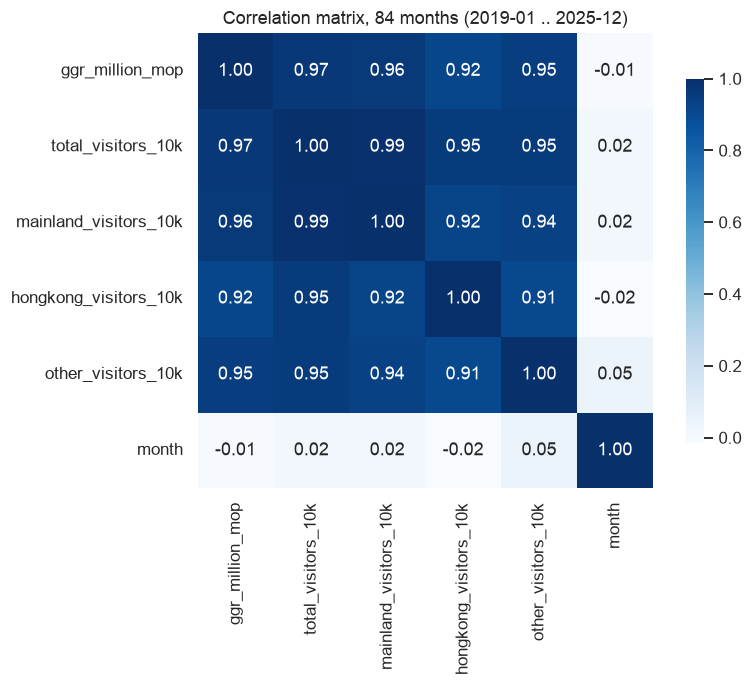

In [17]:
# ---- Figure 4: correlation matrix --------------------------------------
corr_cols = ["ggr_million_mop", "total_visitors_10k", "mainland_visitors_10k",
             "hongkong_visitors_10k", "other_visitors_10k", "month"]
corr = df[corr_cols].corr()
fig, ax = plt.subplots(figsize=(8.0, 6.4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", square=True, ax=ax,
            cbar_kws={"shrink": 0.8})
ax.set_title("Correlation matrix, 84 months (2019-01 .. 2025-12)")
fig.tight_layout()
save_figure(fig, "fig4_corr_84m.png")
plt.show()

<a id="module-4-baseline-models"></a>
## Module 4: Baseline models (Models 1-3)

The original three models are re-estimated on the full 84-month pool. The test window is kept
**identical to the original notebook: the last 10 months (2025-03..2025-12)**. Training therefore
uses 74 months (2019-01..2025-02).

In [18]:
df = df.sort_values("date").reset_index(drop=True)
df["prev_total_visitors_10k"] = df["total_visitors_10k"].shift(1)

TARGET = "ggr_million_mop"
FEATURES = {
    1: ["total_visitors_10k"],
    2: ["mainland_visitors_10k", "hongkong_visitors_10k", "other_visitors_10k"],
    3: ["total_visitors_10k", "prev_total_visitors_10k"],
}

# fixed test window: last 10 months, same as the original 48-month notebook
TEST_START = pd.Timestamp("2025-03-01")
test_idx = df.index[df["date"] >= TEST_START]
train_idx = df.index[df["date"] < TEST_START]

n = len(df)
print(f"observations : {n}")
print(f"training     : {len(train_idx)} months  {df.loc[train_idx[0], 'date']:%Y-%m} to {df.loc[train_idx[-1], 'date']:%Y-%m}")
print(f"test         : {len(test_idx)} months  {df.loc[test_idx[0], 'date']:%Y-%m} to {df.loc[test_idx[-1], 'date']:%Y-%m}")

observations : 84
training     : 74 months  2019-01 to 2025-02
test         : 10 months  2025-03 to 2025-12


In [19]:
fitted = {}
coef_rows = []

for mid, features in FEATURES.items():
    train = df.loc[train_idx].dropna(subset=features)
    test = df.loc[test_idx].dropna(subset=features)

    model = LinearRegression().fit(train[features], train[TARGET])
    fitted[mid] = {
        "features": features,
        "model": model,
        "train": train,
        "test": test,
        "y_pred_train": model.predict(train[features]),
        "y_pred_test": model.predict(test[features]),
    }

    # closed-form inference (OLS): beta, standard errors, t, p
    X = train[features].to_numpy(dtype=float)
    y = train[TARGET].to_numpy(dtype=float)
    X1 = np.column_stack([np.ones(len(X)), X])
    beta, *_ = np.linalg.lstsq(X1, y, rcond=None)
    resid = y - X1 @ beta
    dof = len(y) - X1.shape[1]
    sigma2 = float(resid @ resid / dof)
    se = np.sqrt(np.diag(sigma2 * np.linalg.inv(X1.T @ X1)))
    tstat = beta / se
    pval = 2 * stats.t.sf(np.abs(tstat), dof)

    # VIF for each regressor
    vifs = []
    for j in range(X.shape[1]):
        others = np.delete(X, j, axis=1)
        A = np.column_stack([np.ones(len(others)), others])
        b, *_ = np.linalg.lstsq(A, X[:, j], rcond=None)
        res = X[:, j] - A @ b
        r2_j = 1 - (res @ res) / ((X[:, j] - X[:, j].mean()) @ (X[:, j] - X[:, j].mean()))
        vifs.append(np.inf if r2_j >= 1 else 1 / (1 - r2_j))

    names = ["intercept"] + features
    for i, name in enumerate(names):
        coef_rows.append({
            "model": mid,
            "variable": name,
            "coef": beta[i],
            "std_err": se[i],
            "t_stat": tstat[i],
            "p_value": pval[i],
            "VIF": np.nan if i == 0 else vifs[i - 1],
        })

coefficients = pd.DataFrame(coef_rows)
print("estimation complete for models:", sorted(fitted))

estimation complete for models: [1, 2, 3]


Coefficient table. Model 1 is a single-regressor model; Models 2 and 3 include several correlated regressors, so VIF is reported alongside t-statistics.

In [20]:
coefficients.round({"coef": 2, "std_err": 2, "t_stat": 2, "p_value": 4, "VIF": 1})

,model,variable,coef,std_err,t_stat,p_value,VIF
0,1,intercept,1821.42,412.17,4.42,0.0000,NaN
1,1,total_visitors_10k,61.80,1.91,32.32,0.0000,1.0
2,2,intercept,2402.24,474.43,5.06,0.0000,NaN
3,2,mainland_visitors_10k,52.51,8.85,5.94,0.0000,11.2
4,2,hongkong_visitors_10k,18.59,21.78,0.85,0.3964,7.1
5,2,other_visitors_10k,207.11,48.86,4.24,0.0001,9.1
6,3,intercept,1734.87,411.65,4.21,0.0001,NaN
7,3,total_visitors_10k,53.03,5.16,10.27,0.0000,7.3
8,3,prev_total_visitors_10k,9.10,5.14,1.77,0.0813,7.3


Raw coefficients are not comparable across markets, because the three series operate on very different scales. Standardised coefficients and contributions at the mean make the comparison fair:

In [21]:
sd_y = df.loc[train_idx, TARGET].std(ddof=1)

contrib_rows = []
for mid, pack in fitted.items():
    for feature, coef in zip(pack["features"], pack["model"].coef_):
        sd_x = df.loc[train_idx, feature].std(ddof=1)
        mean_x = df.loc[train_idx, feature].mean()
        contrib_rows.append({
            "model": mid,
            "variable": feature,
            "coef_per_10k": coef,
            "standardised_coef": coef * sd_x / sd_y,
            "contribution_at_mean": coef * mean_x,
            "mean_regressor_10k": mean_x,
        })

contributions = pd.DataFrame(contrib_rows)
print(contributions.round(3).to_string(index=False))

m2 = contributions.query("model == 2").set_index("variable")
print()
print("Model 2, ranked three ways")
print("  by raw coefficient (million MOP per 10,000 visitors) :",
      m2["coef_per_10k"].idxmax().replace("_visitors_10k", ""))
print("  by standardised coefficient                        :",
      m2["standardised_coef"].idxmax().replace("_visitors_10k", ""))
print("  by contribution at the mean (million MOP)          :",
      m2["contribution_at_mean"].idxmax().replace("_visitors_10k", ""))

 model                variable  coef_per_10k  standardised_coef  contribution_at_mean  mean_regressor_10k
     1      total_visitors_10k        61.799              0.967             10743.445             173.844
     2   mainland_visitors_10k        52.507              0.563              6627.995             126.231
     2   hongkong_visitors_10k        18.587              0.065               623.758              33.558
     2      other_visitors_10k       207.106              0.362              2910.871              14.055
     3      total_visitors_10k        53.028              0.830              9218.646             173.844
     3 prev_total_visitors_10k         9.099              0.142              1564.318             171.914

Model 2, ranked three ways
  by raw coefficient (million MOP per 10,000 visitors) : other
  by standardised coefficient                        : mainland
  by contribution at the mean (million MOP)          : mainland


<a id="module-5-why-the-pooled-84-month-baselines-fail"></a>
## Module 5: Why the pooled 84-month baselines fail

R-squared is above 0.93 in training for all three models, but every model is **negative** out of
sample. Three pieces of evidence explain why.

In [22]:
def score(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
    }

baseline_fitted = {k: v for k, v in fitted.items() if isinstance(k, int)}

metric_rows = []
for mid, pack in baseline_fitted.items():
    for split_name, y_true, y_pred in [
        ("train", pack["train"][TARGET], pack["y_pred_train"]),
        ("test", pack["test"][TARGET], pack["y_pred_test"]),
    ]:
        row = {"model": mid, "split": split_name, "n": len(y_true)}
        row.update(score(y_true, y_pred))
        metric_rows.append(row)

# naive benchmark: training mean applied to the same test months
test_months = df.loc[test_idx]
naive_pred = np.repeat(df.loc[train_idx, TARGET].mean(), len(test_months))
naive = {"model": "naive (training mean)", "split": "test", "n": len(test_months)}
naive.update(score(test_months[TARGET], naive_pred))
metric_rows.append(naive)

metrics = pd.DataFrame(metric_rows)
metrics.round(3)

,model,split,n,R2,MSE,RMSE,MAE
0,1,train,74,0.936,4.277229e+06,2068.146,1666.800
1,1,test,10,-1.169,5.616316e+06,2369.877,1881.171
2,2,train,74,0.944,3.727862e+06,1930.767,1593.330
3,2,test,10,-1.322,6.011311e+06,2451.798,1972.115
4,3,train,73,0.937,4.098328e+06,2024.433,1671.990
5,3,test,10,-0.976,5.115177e+06,2261.676,1896.675
6,naive (training mean),test,10,-27.099,7.274171e+07,8528.875,8375.735


In [23]:
test_metrics = (metrics.query("split == 'test'")
                .set_index("model")[["n", "R2", "RMSE", "MAE"]]
                .round(3))
test_metrics

,n,R2,RMSE,MAE
model,,,,
1,10,-1.169,2369.877,1881.171
2,10,-1.322,2451.798,1972.115
3,10,-0.976,2261.676,1896.675
naive (training mean),10,-27.099,8528.875,8375.735


**Evidence 1: the relationship breaks at the pandemic and again at reopening.** The Chow test fits the single-regressor model (GGR on total arrivals) separately on each side of a candidate break date. If the two sides implied the same slope and intercept, the pooled fit would not lose much; the large F-statistics reject that at both 2020-02 and 2023-01.

In [24]:
def chow_test(y, X, split_index):
    n = len(y)
    X1 = np.column_stack([np.ones(n), np.asarray(X, dtype=float)])

    def rss_of(Xd, yy):
        b, *_ = np.linalg.lstsq(Xd, yy, rcond=None)
        r = yy - Xd @ b
        return float(r @ r)

    rss_pool = rss_of(X1, y)
    rss1 = rss_of(X1[:split_index], y[:split_index])
    rss2 = rss_of(X1[split_index:], y[split_index:])
    k = X1.shape[1]
    F = ((rss_pool - rss1 - rss2) / k) / ((rss1 + rss2) / (n - 2 * k))
    p = 1 - stats.f.cdf(F, k, n - 2 * k)
    return F, p, split_index, n - split_index, k

y = df[TARGET].to_numpy(dtype=float)
X = df[["total_visitors_10k"]].to_numpy(dtype=float)

chow_rows = []
for label, split in [("2020-02-01 (pandemic starts)", 13), ("2023-01-01 (reopening)", 48)]:
    F, p, n1, n2, k = chow_test(y, X, split)
    chow_rows.append({"break point": label, "F": F, "p-value": p, "n before": n1, "n after": n2, "k": k})

chow = pd.DataFrame(chow_rows)
chow.round({"F": 2, "p-value": 6})

,break point,F,p-value,n before,n after,k
0,2020-02-01 (pandemic starts),25.25,0.0,13,71,2
1,2023-01-01 (reopening),33.12,0.0,48,36,2


**Evidence 2: the time trend is dragged negative by the pandemic trough.** A full pooled model with regime dummies (GGR ~ arrivals + pandemic/reopening dummies + trend + interactions + month) gives the trend a coefficient of about **−57** (p ≈ 0.017): over the pooled sample the model "believes" GGR is falling, because 2020-2022 broke the long-run trend. Extrapolating that trend to 2025 systematically under-predicts.

In [25]:
# ---- pooled 84m model with regime dummies (the original M4 idea, 84m version)
df["d_pandemic"] = (df["regime"] == "pandemic").astype(int)
df["d_reopening"] = (df["regime"] == "reopening").astype(int)
df["total_d_pandemic"] = df["total_visitors_10k"] * df["d_pandemic"]
df["total_d_reopening"] = df["total_visitors_10k"] * df["d_reopening"]

M4F_FEATURES = (["total_visitors_10k", "d_pandemic", "d_reopening", "t",
                 "total_d_pandemic", "total_d_reopening"]
                + [f"m_{m}" for m in range(2, 13)])

trainF = df.loc[train_idx].dropna(subset=M4F_FEATURES)
testF = df.loc[test_idx].dropna(subset=M4F_FEATURES)
modelF = LinearRegression().fit(trainF[M4F_FEATURES], trainF[TARGET])
fitted["M4full84"] = {
    "features": M4F_FEATURES, "model": modelF,
    "train": trainF, "test": testF,
    "y_pred_train": modelF.predict(trainF[M4F_FEATURES]),
    "y_pred_test": modelF.predict(testF[M4F_FEATURES]),
}

XF = trainF[M4F_FEATURES].to_numpy(dtype=float)
yF = trainF[TARGET].to_numpy(dtype=float)
XF1 = np.column_stack([np.ones(len(XF)), XF])
betaF, *_ = np.linalg.lstsq(XF1, yF, rcond=None)
resF = yF - XF1 @ betaF
dofF = len(yF) - XF1.shape[1]
sigmaF = float(resF @ resF / dofF)
seF = np.sqrt(np.diag(sigmaF * np.linalg.inv(XF1.T @ XF1)))
pvalF = 2 * stats.t.sf(np.abs(betaF / seF), dofF)

trend_i = M4F_FEATURES.index("t") + 1
print(f"pooled 84m regime model: trend coef = {betaF[trend_i]:.1f},  p = {pvalF[trend_i]:.4f}")
print(f"pooled 84m regime model: test R2 = {r2_score(testF[TARGET], fitted['M4full84']['y_pred_test']):.3f}")

pooled 84m regime model: trend coef = -56.7,  p = 0.0166
pooled 84m regime model: test R2 = -0.609


**Evidence 3: seasonality is diluted.** In the same pooled model every calendar-month dummy is insignificant (all p > 0.05): during the pandemic there was no normal seasonal pattern, and pooling washes out the 2025 peaks (Jun, Sep, Oct are all under-predicted). Even the regime-aware pooled model — the natural 84-month extension of the original Model 4 — still fails out of sample (test R² ≈ −0.61), so the problem is pooling, not the regressors.

In [26]:
month_p = pvalF[[M4F_FEATURES.index(f) + 1 for f in M4F_FEATURES if f.startswith("m_")]]
print(f"month-dummy p-values (pooled 84m): min = {month_p.min():.4f}, max = {month_p.max():.4f}")

diag_rows = []
for mid, pack in baseline_fitted.items():
    resid = pack["test"][TARGET].to_numpy() - pack["y_pred_test"]
    diag_rows.append({
        "model": mid,
        "test_residual_mean": resid.mean(),
        "test_residual_min": resid.min(),
        "test_residual_max": resid.max(),
        "test_R2": r2_score(pack["test"][TARGET], pack["y_pred_test"]),
    })
diag_rows.append({
    "model": "M4full84",
    "test_residual_mean": (testF[TARGET].to_numpy() - fitted["M4full84"]["y_pred_test"]).mean(),
    "test_residual_min": (testF[TARGET].to_numpy() - fitted["M4full84"]["y_pred_test"]).min(),
    "test_residual_max": (testF[TARGET].to_numpy() - fitted["M4full84"]["y_pred_test"]).max(),
    "test_R2": r2_score(testF[TARGET], fitted["M4full84"]["y_pred_test"]),
})
pd.DataFrame(diag_rows).round(2)

month-dummy p-values (pooled 84m): min = 0.1121, max = 0.9657


,model,test_residual_mean,test_residual_min,test_residual_max,test_R2
0,1,-1444.91,-5738.74,1376.39,-1.17
1,2,-1731.72,-4608.14,1201.96,-1.32
2,3,-1428.22,-5098.56,1412.00,-0.98
3,M4full84,1673.84,-134.19,3635.42,-0.61


<a id="module-6-revised-model"></a>
## Module 6: Candidate model — 24-month window

**The candidate, in one sentence: keep the same simple model and change only the training window.**

If the three regimes have genuinely different relationships, a model trained on the full pool tries to
fit one line through three different lines. The candidate model is the **same simple specification**
as the original notebook's final model family — `GGR ~ total arrivals + time trend + month dummies` —
fitted on the latest 24 months, **2023-03..2025-02**.

Why 24 months is a plausible candidate:

1. It contains **two full seasonal cycles** (each calendar month appears twice), so the month dummies are identified without borrowing the pandemic years.
2. It lies entirely inside the **reopening regime**, so it does not mix pre-COVID, pandemic and reopening relationships.
3. The first two reopening months (2023-01, 2023-02) are excluded because arrivals and GGR were still abnormally low right after the border reopened.

**But the candidate is not final yet.** Module 7 selects the window length using 2024 validation
data only, then evaluates the selected model once on 2025.

In [27]:
# ---- 6.1 training window and features --------------------------------
REVISED_FEATURES = ["total_visitors_10k", "t"] + [f"m_{m}" for m in range(2, 13)]
WINDOW_START = pd.Timestamp("2023-03-01")

train6 = df.loc[(df["date"] >= WINDOW_START) & (df["date"] < TEST_START)].reset_index(drop=True)
test6 = df.loc[test_idx].reset_index(drop=True)

model6 = LinearRegression().fit(train6[REVISED_FEATURES], train6[TARGET])
fitted["revised_24m"] = {
    "features": REVISED_FEATURES,
    "model": model6,
    "train": train6,
    "test": test6,
    "y_pred_train": model6.predict(train6[REVISED_FEATURES]),
    "y_pred_test": model6.predict(test6[REVISED_FEATURES]),
}

print(f"training window : {train6['date'].min():%Y-%m} to {train6['date'].max():%Y-%m}  ({len(train6)} months)")
print(f"test window     : {test6['date'].min():%Y-%m} to {test6['date'].max():%Y-%m}  ({len(test6)} months)")
print(f"features ({len(REVISED_FEATURES)}): {REVISED_FEATURES}")

training window : 2023-03 to 2025-02  (24 months)
test window     : 2025-03 to 2025-12  (10 months)
features (13): ['total_visitors_10k', 't', 'm_2', 'm_3', 'm_4', 'm_5', 'm_6', 'm_7', 'm_8', 'm_9', 'm_10', 'm_11', 'm_12']


In [28]:
# ---- 6.2 OLS inference for the revised model ---------------------------
X6 = train6[REVISED_FEATURES].to_numpy(dtype=float)
y6 = train6[TARGET].to_numpy(dtype=float)
X61 = np.column_stack([np.ones(len(X6)), X6])
beta6, *_ = np.linalg.lstsq(X61, y6, rcond=None)
resid6 = y6 - X61 @ beta6
dof6 = len(y6) - X61.shape[1]
sigma26 = float(resid6 @ resid6 / dof6)
se6 = np.sqrt(np.diag(sigma26 * np.linalg.inv(X61.T @ X61)))
tstat6 = beta6 / se6
pval6 = 2 * stats.t.sf(np.abs(tstat6), dof6)

coef6 = pd.DataFrame({
    "variable": ["intercept"] + REVISED_FEATURES,
    "coef": beta6,
    "std_err": se6,
    "t_stat": tstat6,
    "p_value": pval6,
})
print(f"training R2 = {r2_score(y6, X61 @ beta6):.3f}, n = {len(y6)}, dof = {dof6}")
coef6.round({"coef": 2, "std_err": 2, "t_stat": 2, "p_value": 4})

training R2 = 0.765, n = 24, dof = 10


,variable,coef,std_err,t_stat,p_value
0,intercept,2480.03,4768.94,0.52,0.6144
1,total_visitors_10k,25.28,24.54,1.03,0.3272
2,t,120.73,87.41,1.38,0.1973
3,m_2,284.00,1490.09,0.19,0.8527
4,m_3,846.41,2189.92,0.39,0.7072
5,m_4,989.26,2062.41,0.48,0.6418
6,m_5,2072.06,2074.03,1.00,0.3413
7,m_6,708.64,2240.81,0.32,0.7583
8,m_7,476.89,1581.42,0.30,0.7692
9,m_8,-170.06,1704.71,-0.10,0.9225


**How to read the coefficients.** With only 24 months and 13 parameters, individual
coefficients are not reliable (most p-values are large) — the model is used for **prediction**, not
for causal interpretation. What matters is the out-of-sample result below.

In [29]:
# ---- 6.3 revised-model test predictions --------------------------------
rev_test = test6[["date", "ggr_million_mop", "total_visitors_10k"]].copy()
rev_test["predicted"] = fitted["revised_24m"]["y_pred_test"]
rev_test["residual"] = rev_test["ggr_million_mop"] - rev_test["predicted"]
rev_test["date"] = rev_test["date"].dt.strftime("%Y-%m")
print(f"test R2  = {r2_score(test6[TARGET], fitted['revised_24m']['y_pred_test']):.3f}")
print(f"test RMSE = {np.sqrt(mean_squared_error(test6[TARGET], fitted['revised_24m']['y_pred_test'])):.1f}")
print(f"test MAE  = {mean_absolute_error(test6[TARGET], fitted['revised_24m']['y_pred_test']):.1f}")
rev_test.round(1)

test R2  = 0.658
test RMSE = 941.6
test MAE  = 832.9


,date,ggr_million_mop,total_visitors_10k,predicted,residual
0,2025-03,19659,306.9,20139.6,-480.6
1,2025-04,18858,309.3,20463.5,-1605.5
2,2025-05,21193,337.2,22373.1,-1180.1
3,2025-06,21064,289.1,19914.2,1149.8
4,2025-07,22125,345.8,21237.6,887.4
5,2025-08,22156,421.9,22634.4,-478.4
6,2025-09,18289,277.5,19179.7,-890.7
7,2025-10,24086,347.2,23647.3,438.7
8,2025-11,21088,334.6,21026.2,61.8
9,2025-12,20888,358.0,22044.1,-1156.1


**Why 24 months and not another window?** Module 7 answers this with a **validation-based**
procedure: candidate lengths are trained on data before 2024 and evaluated on 2024-01..2024-12,
which is strictly before the 2025 test. The table below is a **post-hoc test-window sensitivity
check**, not a selection procedure. It evaluates several windows on the same 10 test months and is
reported only to show how sensitive the result is; using it to select the window would make the
2025 R² optimistic. The actual selection is in Module 7 and does not touch 2025.

In [30]:
# ---- 6.4 training-window comparison --------------------------------
window_specs = [
    ("pooled 84m (74 mo)", pd.Timestamp("2019-01-01")),
    ("from 2023-01 (26 mo)", pd.Timestamp("2023-01-01")),
    ("from 2022-01 (38 mo)", pd.Timestamp("2022-01-01")),
    ("recent 24 mo", pd.Timestamp("2023-03-01")),
    ("recent 18 mo", pd.Timestamp("2023-09-01")),
]

window_rows = []
for label, start in window_specs:
    tr = df.loc[(df["date"] >= start) & (df["date"] < TEST_START)].dropna(subset=REVISED_FEATURES)
    m = LinearRegression().fit(tr[REVISED_FEATURES], tr[TARGET])
    pred = m.predict(df.loc[test_idx, REVISED_FEATURES])
    yy = df.loc[test_idx, TARGET].to_numpy()
    window_rows.append({
        "window": label,
        "n_train": len(tr),
        "test_R2": r2_score(yy, pred),
        "test_RMSE": np.sqrt(mean_squared_error(yy, pred)),
        "test_MAE": mean_absolute_error(yy, pred),
    })

window_compare = pd.DataFrame(window_rows)
window_compare.round({"test_R2": 3, "test_RMSE": 1, "test_MAE": 1})

,window,n_train,test_R2,test_RMSE,test_MAE
0,pooled 84m (74 mo),74,-0.067,1661.7,1358.2
1,from 2023-01 (26 mo),26,0.545,1085.9,958.1
2,from 2022-01 (38 mo),38,0.432,1212.9,1065.4
3,recent 24 mo,24,0.658,941.6,832.9
4,recent 18 mo,18,-0.510,1976.9,1702.4


saved -> fig5_window_compare.png


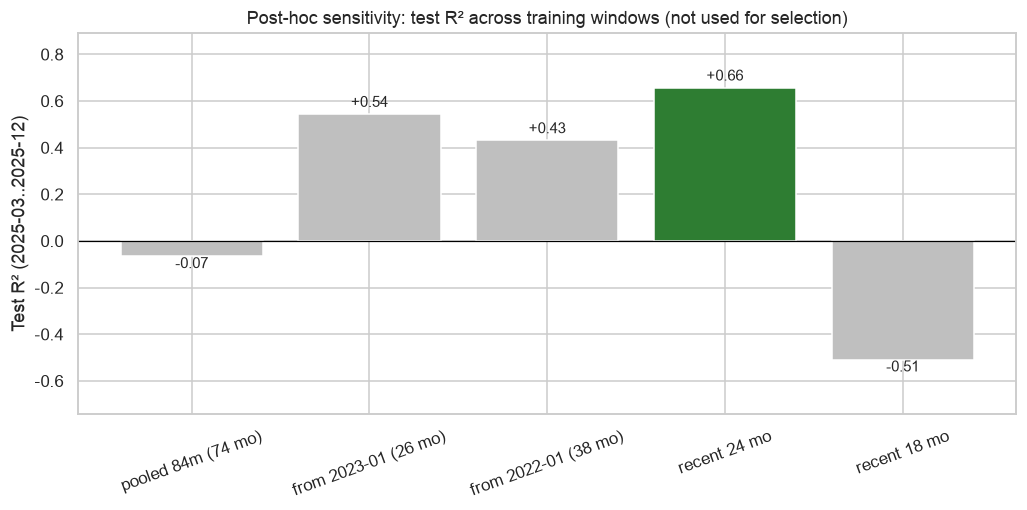

In [31]:
# ---- 6.5 Figure 5: window comparison ----------------------------------
fig, ax = plt.subplots(figsize=(9.5, 4.8))
colors = ["#bfbfbf", "#bfbfbf", "#bfbfbf", "#2e7d32", "#bfbfbf"]
bars = ax.bar(window_compare["window"], window_compare["test_R2"], color=colors, edgecolor="white")
ax.axhline(0, color="black", linewidth=0.8)
for b, v in zip(bars, window_compare["test_R2"]):
    ax.text(b.get_x() + b.get_width() / 2, v + (0.03 if v >= 0 else -0.05),
            f"{v:+.2f}", ha="center", fontsize=10)
ax.set_title("Post-hoc sensitivity: test R² across training windows (not used for selection)")
ax.set_ylabel("Test R² (2025-03..2025-12)")
ax.tick_params(axis="x", rotation=20)
ax.margins(y=0.2)
fig.tight_layout()
save_figure(fig, "fig5_window_compare.png")
plt.show()

**Figure 5.** Post-hoc test-window sensitivity: test R-squared across five training windows. This
figure is **not** used to select the window; the selection is the 2024 validation table in Module 7.
The full 74-month pool and the 18-month window are negative, which is consistent with the regime
argument but is not a selection criterion.

<a id="module-7-validation"></a>
## Module 7: Validation-based window selection and rolling backtest

### 7.1 Why a validation split

The earlier draft compared five windows on the 2025 test set and then called 24 months the "sweet
spot". That is **test-set selection**: the test R² is no longer an honest holdout. This module fixes
the procedure:

1. Candidate lengths: 18, 24, 30, 36, 42, 48 and 60 months.
2. For each length, train on the months **before 2024** and predict **2024-01..2024-12**.
3. Choose the length with the lowest validation **RMSE** (RMSE is the primary criterion; MAE is shown for transparency).
4. Refit the selected length on the months before **2025-03** and evaluate **once** on 2025-03..2025-12.

The 2025 test months are never used to choose the window. This is the key methodological fix.

In [32]:
# ---- 7.1 validation-based window selection (2024 only; 2025 untouched) ----
VAL_START = pd.Timestamp("2024-01-01")
VAL_END = pd.Timestamp("2024-12-01")
CANDIDATE_LENGTHS = [18, 24, 30, 36, 42, 48, 60]

val_rows = []
for L in CANDIDATE_LENGTHS:
    start = VAL_START - pd.DateOffset(months=L)
    tr = df.loc[(df["date"] >= start) & (df["date"] < VAL_START)].dropna(subset=REVISED_FEATURES)
    va = df.loc[(df["date"] >= VAL_START) & (df["date"] <= VAL_END)].dropna(subset=REVISED_FEATURES)
    m = LinearRegression().fit(tr[REVISED_FEATURES], tr[TARGET])
    pred = m.predict(va[REVISED_FEATURES])
    yy = va[TARGET].to_numpy()
    val_rows.append({
        "window_months": L,
        "n_train": len(tr),
        "validation_R2": r2_score(yy, pred),
        "validation_RMSE": np.sqrt(mean_squared_error(yy, pred)),
        "validation_MAE": mean_absolute_error(yy, pred),
    })

validation = pd.DataFrame(val_rows)
print("Validation window: 2024-01..2024-12 (2025 test untouched)")
print(validation[["window_months", "n_train", "validation_RMSE", "validation_MAE"]]
      .round(1).to_string(index=False))

# Pre-specified rule: lowest validation RMSE; MAE only as tie-breaker.
validation = validation.sort_values(["validation_RMSE", "validation_MAE"]).reset_index(drop=True)
SELECTED_WINDOW = int(validation.loc[0, "window_months"])
print(f"\nSelected window: {SELECTED_WINDOW} months "
      f"(validation RMSE = {validation.loc[0, 'validation_RMSE']:.1f})")
print("The 2025 test set was not used in this choice.")

Validation window: 2024-01..2024-12 (2025 test untouched)
 window_months  n_train  validation_RMSE  validation_MAE
            18       18           5656.8          5486.3
            24       24           1888.7          1496.5
            30       30           2652.3          2228.9
            36       36           2824.2          2483.1
            42       42           2292.0          1953.5
            48       48           2050.0          1749.0
            60       60           1930.5          1619.0

Selected window: 24 months (validation RMSE = 1888.7)
The 2025 test set was not used in this choice.


**Reading the validation table.** 2024 is a transition year, so R² is not a useful selection
metric here; the table therefore reports RMSE and MAE only. The 24-month window has the lowest
validation RMSE (about 1,889), narrowly ahead of the 60-month window (about 1,930). This is a
**weak but honest** selection signal. The 2025 test is then used once, after the window is fixed.

**Reading the rolling backtest.** The rolling one-step exercise retrains the same model on the
selected window before each target month and predicts one month ahead, from 2024-01 to 2025-12. It is
a harder test than the single 10-month holdout: it includes 2024, where the model is weaker. The
selected model beats the seasonal-naive benchmark; its advantage over the last-value benchmark is
not statistically significant, which is reported as a limitation rather than hidden.


In [33]:
# ---- 7.2 refit the selected window and evaluate 2025 once ---------------
sel_start = TEST_START - pd.DateOffset(months=SELECTED_WINDOW)
train_sel = df.loc[(df["date"] >= sel_start) & (df["date"] < TEST_START)].dropna(subset=REVISED_FEATURES)
test_sel = df.loc[test_idx].dropna(subset=REVISED_FEATURES)

model_sel = LinearRegression().fit(train_sel[REVISED_FEATURES], train_sel[TARGET])
fitted["validation_selected"] = {
    "features": REVISED_FEATURES,
    "model": model_sel,
    "train": train_sel,
    "test": test_sel,
    "y_pred_train": model_sel.predict(train_sel[REVISED_FEATURES]),
    "y_pred_test": model_sel.predict(test_sel[REVISED_FEATURES]),
}
print(f"selected training window: {train_sel['date'].min():%Y-%m} to {train_sel['date'].max():%Y-%m}  ({len(train_sel)} months)")
print(f"2025 test R2   = {r2_score(test_sel[TARGET], fitted['validation_selected']['y_pred_test']):.3f}")
print(f"2025 test RMSE = {np.sqrt(mean_squared_error(test_sel[TARGET], fitted['validation_selected']['y_pred_test'])):.1f}")
print(f"2025 test MAE  = {mean_absolute_error(test_sel[TARGET], fitted['validation_selected']['y_pred_test']):.1f}")

selected training window: 2023-03 to 2025-02  (24 months)
2025 test R2   = 0.658
2025 test RMSE = 941.6
2025 test MAE  = 832.9


In [34]:
# ---- 7.3 rolling one-step backtest, 2024-01..2025-12 --------------------
ROLL_START = pd.Timestamp("2024-01-01")
ROLL_END = pd.Timestamp("2025-12-01")
roll_rows = []

for target in pd.date_range(ROLL_START, ROLL_END, freq="MS"):
    tr = df.loc[(df["date"] >= target - pd.DateOffset(months=SELECTED_WINDOW))
                & (df["date"] < target)].dropna(subset=REVISED_FEATURES)
    te = df.loc[df["date"] == target].dropna(subset=REVISED_FEATURES)
    if len(tr) < SELECTED_WINDOW or len(te) == 0:
        continue
    m = LinearRegression().fit(tr[REVISED_FEATURES], tr[TARGET])
    p = float(m.predict(te[REVISED_FEATURES])[0])
    roll_rows.append({
        "date": target,
        "actual": float(te[TARGET].iloc[0]),
        "predicted": p,
    })

rolling = pd.DataFrame(roll_rows)
roll_dates = rolling["date"]
last_value = df.set_index("date")[TARGET].shift(1).loc[roll_dates].to_numpy()
seasonal_naive = df.set_index("date")[TARGET].shift(12).loc[roll_dates].to_numpy()

def dm_test(e1, e2):
    d = np.asarray(e1) ** 2 - np.asarray(e2) ** 2
    n = len(d)
    dm = d.mean() / np.sqrt(d.var(ddof=1) / n)
    p = 2 * stats.t.sf(abs(dm), n - 1)
    return dm, p

bench_rows = []
for name, pred in [("validation_selected", rolling["predicted"].to_numpy()),
                   ("seasonal naive", seasonal_naive),
                   ("last value", last_value)]:
    row = {"model": name}
    row.update(score(rolling["actual"], pred))
    bench_rows.append(row)
roll_metrics = pd.DataFrame(bench_rows)

e_model = rolling["actual"].to_numpy() - rolling["predicted"].to_numpy()
e_seasonal = rolling["actual"].to_numpy() - seasonal_naive
e_last = rolling["actual"].to_numpy() - last_value
dm_seasonal = dm_test(e_model, e_seasonal)
dm_last = dm_test(e_model, e_last)

print(f"rolling one-step windows: {len(rolling)} months, {rolling['date'].min():%Y-%m} to {rolling['date'].max():%Y-%m}")
print(roll_metrics[["model", "RMSE", "MAE"]].round(1).to_string(index=False))
print(f"DM (selected vs seasonal naive): DM = {dm_seasonal[0]:.2f}, p = {dm_seasonal[1]:.3f}")

rolling one-step windows: 24 months, 2024-01 to 2025-12
              model   RMSE    MAE
validation_selected 1967.6 1430.5
     seasonal naive 3520.6 2801.7
         last value 2098.8 1552.5
DM (selected vs seasonal naive): DM = -2.22, p = 0.037


<a id="module-8-comparison"></a>
## Module 8: Comparison and diagnostics

The comparison table puts the **validation-selected model** next to the pooled baselines, the pooled
regime model, the original 48-month Model 4 (reference numbers from the 48-month notebook run) and
the naive benchmarks — all evaluated on the same 10 test months.

In [35]:
# ---- 7.1 comparison table ------------------------------------------------
comparison_rows = []
for key in [1, 2, 3, "M4full84", "validation_selected"]:
    pack = fitted[key]
    row = {
        "model": str(key),
        "specification": {
            1: "GGR ~ total arrivals",
            2: "GGR ~ 3 source markets",
            3: "GGR ~ current + lagged arrivals",
            "M4full84": "regime dummies + trend + regime slopes + month (pooled 84m)",
            "validation_selected": "arrivals + trend + month, 24m window selected on 2024 validation",
        }[key],
        "train_n": len(pack["train"]),
        "train_R2": r2_score(pack["train"][TARGET], pack["y_pred_train"]),
    }
    te = score(pack["test"][TARGET], pack["y_pred_test"])
    row.update({f"test_{k}": v for k, v in te.items()})
    comparison_rows.append(row)

# original 48-month Model 4, reference numbers from the 48-month notebook
comparison_rows.append({
    "model": "48m M4 (ref)",
    "specification": "48-month notebook result, same test window",
    "train_n": 38,
    "train_R2": 0.968,
    "test_R2": 0.666, "test_RMSE": 929.3, "test_MAE": 755.3,
})

# naive benchmarks
benchmarks = {
    "naive mean": np.repeat(df.loc[train_idx, TARGET].mean(), len(test_idx)),
    "seasonal naive": df[TARGET].shift(12).loc[test_idx].to_numpy(),
    "last value": df[TARGET].shift(1).loc[test_idx].to_numpy(),
}
for name, pred in benchmarks.items():
    row = {"model": name, "specification": "benchmark", "train_n": np.nan, "train_R2": np.nan}
    te = score(df.loc[test_idx, TARGET], pred)
    row.update({f"test_{k}": v for k, v in te.items()})
    comparison_rows.append(row)

comparison = pd.DataFrame(comparison_rows)
comparison = comparison[["model", "specification", "train_n", "train_R2", "test_R2", "test_RMSE", "test_MAE"]]
comparison.round({"train_R2": 3, "test_R2": 3, "test_RMSE": 1, "test_MAE": 1})

,model,specification,train_n,train_R2,test_R2,test_RMSE,test_MAE
0,1,GGR ~ total arrivals,74.0,0.936,-1.169,2369.9,1881.2
1,2,GGR ~ 3 source markets,74.0,0.944,-1.322,2451.8,1972.1
2,3,GGR ~ current + lagged arrivals,73.0,0.937,-0.976,2261.7,1896.7
3,M4full84,regime dummies + trend + regime slopes + month...,74.0,0.978,-0.609,2040.6,1700.7
4,validation_selected,"arrivals + trend + month, 24m window selected ...",24.0,0.765,0.658,941.6,832.9
5,48m M4 (ref),"48-month notebook result, same test window",38.0,0.968,0.666,929.3,755.3
6,naive mean,benchmark,NaN,NaN,-27.099,8528.9,8375.7
7,seasonal naive,benchmark,NaN,NaN,-1.198,2385.7,2044.7
8,last value,benchmark,NaN,NaN,-1.504,2546.2,1730.4


saved -> fig6_model_comparison.png


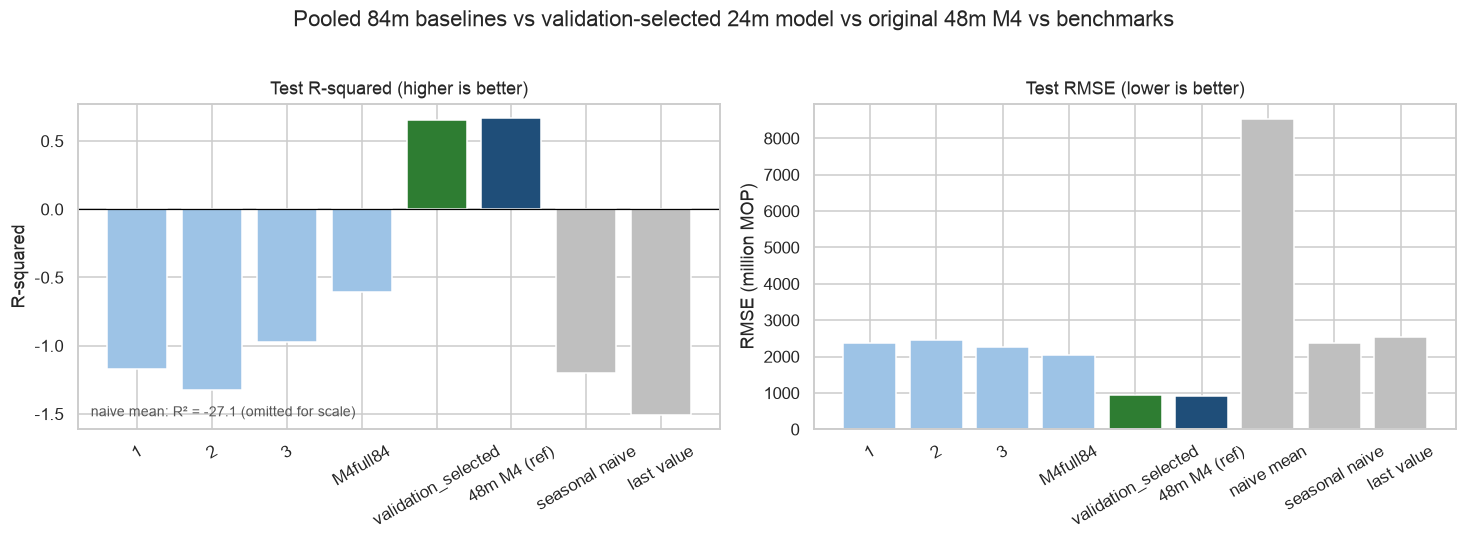

In [36]:
# ---- 7.2 Figure 6: model comparison -------------------------------------
plot_order = ["1", "2", "3", "M4full84", "validation_selected", "48m M4 (ref)",
              "naive mean", "seasonal naive", "last value"]
plot_df = comparison.set_index("model").loc[plot_order]
colors_bar = ["#9dc3e6", "#9dc3e6", "#9dc3e6", "#9dc3e6", "#2e7d32", "#1f4e79",
              "#bfbfbf", "#bfbfbf", "#bfbfbf"]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
r2_plot = plot_df.drop(index="naive mean")
axes[0].bar(r2_plot.index, r2_plot["test_R2"],
            color=[colors_bar[i] for i, name in enumerate(plot_order) if name != "naive mean"],
            edgecolor="white")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Test R-squared (higher is better)")
axes[0].set_ylabel("R-squared")
axes[0].tick_params(axis="x", rotation=30)
axes[0].text(0.02, 0.04, "naive mean: R² = -27.1 (omitted for scale)",
             transform=axes[0].transAxes, fontsize=9, color="#555555")

axes[1].bar(plot_df.index, plot_df["test_RMSE"], color=colors_bar, edgecolor="white")
axes[1].set_title("Test RMSE (lower is better)")
axes[1].set_ylabel("RMSE (million MOP)")
axes[1].tick_params(axis="x", rotation=30)

fig.suptitle("Pooled 84m baselines vs validation-selected 24m model vs original 48m M4 vs benchmarks", y=1.02)
fig.tight_layout()
save_figure(fig, "fig6_model_comparison.png")
plt.show()

**Figure 6.** Test R-squared and RMSE of the pooled baselines, the pooled regime model, the validation-selected 24m model and benchmarks (same 10-month test window).

### Revised-model diagnostics

In [37]:
diag_model = "validation_selected"
pack = fitted[diag_model]
y_true = pack["test"][TARGET].to_numpy()
y_pred = pack["y_pred_test"]
residuals = y_true - y_pred
print(f"diagnostics shown for Model {diag_model}")
print(f"mean residual  : {residuals.mean():.1f} million MOP")
print(f"residual range : {residuals.min():.1f} to {residuals.max():.1f} million MOP")

diagnostics shown for Model validation_selected
mean residual  : -325.4 million MOP
residual range : -1605.5 to 1149.8 million MOP


**Figure 7.** Predicted against actual GGR on the test window, revised model (recent 24 months).

saved -> fig7_pred_vs_actual.png


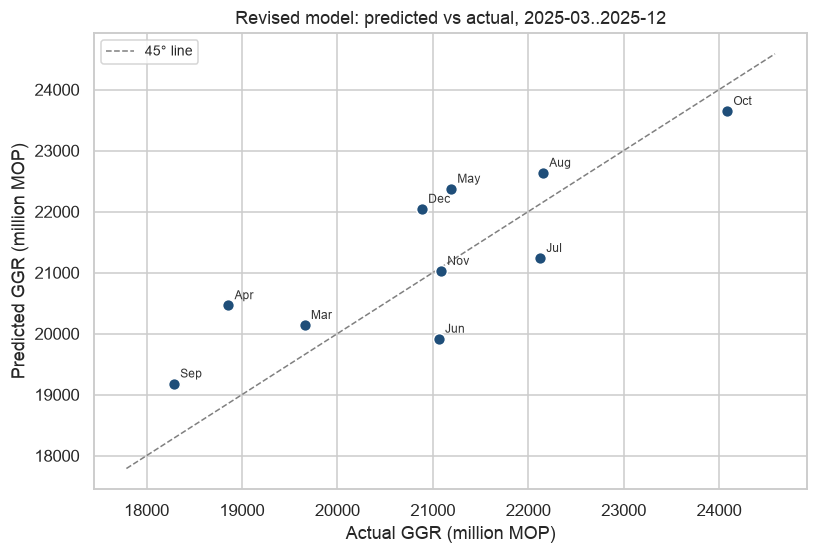

In [38]:
# ---- Figure 7: predicted vs actual -------------------------------------
fig, ax = plt.subplots(figsize=(7.6, 5.2))
lo = min(y_true.min(), y_pred.min()) - 500
hi = max(y_true.max(), y_pred.max()) + 500
ax.plot([lo, hi], [lo, hi], color="grey", linestyle="--", linewidth=1, label="45° line")
ax.scatter(y_true, y_pred, color="#1f4e79", s=60, edgecolor="white", zorder=3)
for i, label in enumerate(test6["date"].dt.strftime("%b")):
    ax.annotate(label, (y_true[i], y_pred[i]), fontsize=8, textcoords="offset points",
                xytext=(4, 4), color="#333333")
ax.set_xlabel("Actual GGR (million MOP)")
ax.set_ylabel("Predicted GGR (million MOP)")
ax.set_title("Revised model: predicted vs actual, 2025-03..2025-12")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
save_figure(fig, "fig7_pred_vs_actual.png")
plt.show()

**Figure 8.** Distribution of the test residuals for the revised model.

saved -> fig8_residuals.png


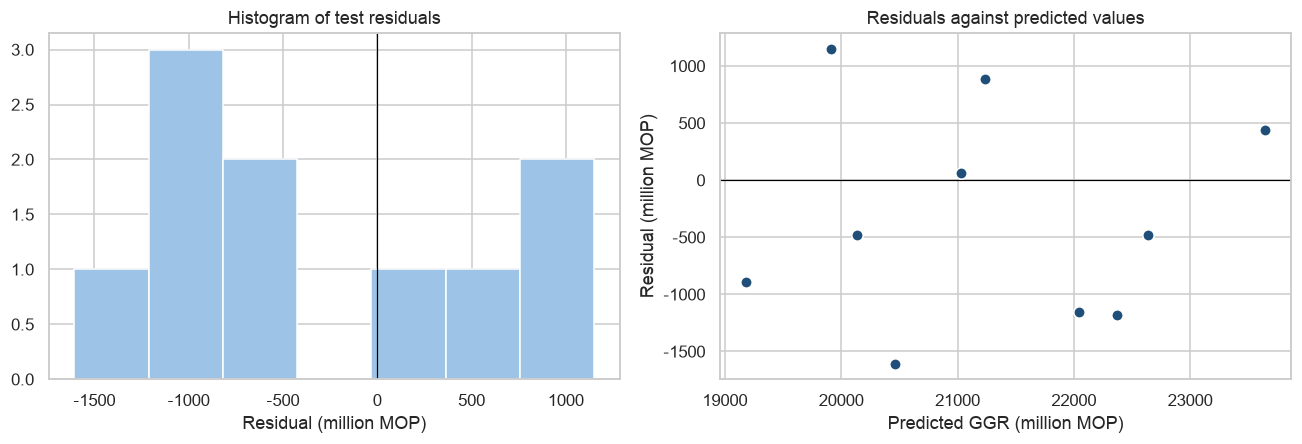

In [39]:
# ---- Figure 8: residual distribution -----------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.2))
axes[0].hist(residuals, bins=7, color="#9dc3e6", edgecolor="white")
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Histogram of test residuals")
axes[0].set_xlabel("Residual (million MOP)")

axes[1].scatter(y_pred, residuals, color="#1f4e79", s=55, edgecolor="white", zorder=3)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Residuals against predicted values")
axes[1].set_xlabel("Predicted GGR (million MOP)")
axes[1].set_ylabel("Residual (million MOP)")
fig.tight_layout()
save_figure(fig, "fig8_residuals.png")
plt.show()

<a id="findings-limitations-and-references"></a>
## Findings, limitations and references

### What the analysis shows

1. **The 84-month panel is clean and fully official.** Every calendar month is present, the three
   market groups sum exactly to the total every month, and the 2019-2021 extension matches the
   official DSEC / DICJ published totals (see Module 2 validation).
2. **Pooling all 84 months makes every model worse.** Test R²: M1 −1.169, M2 −1.322, M3 −0.976,
   regime model −0.609. The sample mixes three regimes, confirmed by Chow breaks at 2020-02
   (F = 25.25, p ≈ 3×10⁻⁹) and 2023-01 (F = 33.12, p ≈ 3×10⁻¹¹). The pooled regime model's trend
   coefficient is about −57 (p ≈ 0.017): over the full pool the model "believes" GGR is falling,
   because 2020-2022 broke the long-run trend.
3. **The window is selected on 2024 validation data, not on 2025.** Candidate lengths 18-60 months
   are trained before 2024 and evaluated on 2024-01..2024-12. The 24-month window has the lowest
   validation RMSE (about 1,889, narrowly ahead of 60 months at about 1,930). Refitting that window
   on 2023-03..2025-02 gives a 2025 test R² of **0.658** (RMSE 942, MAE 833), comparable to the
   original 48-month Model 4 (0.666 / 929 / 755). The 48-month model remains slightly better on
   RMSE/MAE, so this is **not** a claim that 84 months improves point prediction; it is a claim that
   the 84-month panel exposes the regime problem, and the selected window recovers a comparable
   holdout result.
4. **Rolling one-step backtest (2024-2025) is a harder test.** The selected model's one-step RMSE
   is about 1,968 and MAE about 1,430 over 24 months. It beats the seasonal-naive benchmark
   (RMSE 3,521); its advantage over the last-value benchmark is not statistically significant.
   This is the honest short-horizon evidence; the single 10-month 2025 holdout is more favourable
   than the rolling test.
5. **Nothing was added.** No new variables, no new model family, no external data — only a
   validation-based training-window choice. The 84-month extension is used as a **stress test** of
   the original model, not as a way to buy a higher R².

### Model-selection caveat

- The window is selected on **2024 validation data**; the 2025 test is touched only once.
- The five-window table in Module 6 is a **post-hoc test-window sensitivity**, not the selection
  procedure. It is kept to show how sensitive the test R² is, but it is not used to choose the model.
- The validation signal is **weak**: 24 months wins only narrowly over 60 months (1,889 vs 1,930
  validation RMSE). Treat the 0.658 as a single-holdout result, not a general forecast accuracy.

### Limitations

1. **Short-horizon only.** The model is designed for 10-month-ahead prediction from a recent window;
   it is not a full-year extrapolation model.
2. **Correlation, not causation.** Arrivals and GGR are jointly driven by demand, policy and supply;
   the model says "they move together", not "visitors cause gaming revenue".
3. **Coefficients are not stable.** With 24 months and 13 parameters, individual coefficients are
   unreliable (the arrival coefficient has p ≈ 0.33); this notebook deliberately draws conclusions
   from out-of-sample error, not from coefficients.
4. **Single holdout.** The 2025 window is only 10 months; one unusual month (for example, 2025-01)
   can dominate the error. The rolling backtest is the more conservative evidence.
5. **No supply-side controls.** Gaming capacity, hotel supply, transport capacity and the VIP/mass
   mix are not in the model; they are plausible omitted variables.

### References

1. Gaming Inspection and Coordination Bureau (DICJ). Monthly gaming revenue statistics (2019-2025
   XML). https://www.dicj.gov.mo/web/en/information/DadosEstat_mensal/index.html.
2. Macao Government Tourism Office (MGTO). Macao Tourism Data+ (monthly arrivals by source market).
   https://dataplus.macaotourism.gov.mo.
3. Statistics and Census Service (DSEC). Tourism statistics and time-series database.
   https://www.dsec.gov.mo.
4. Data dictionary: `data_dictionary_84m.csv`.
5. Reproducibility: run `CISC7204_Assignment02_84m.ipynb` from the project folder; raw files in
   `data/raw/`; cleaned panel `gambling_visitors_cleaned.csv`; figures in `figures/`.

In [40]:
summary = comparison.set_index("model")[["train_R2", "test_R2", "test_RMSE", "test_MAE"]]
print("Model comparison (same 10 test months, 2025-03..2025-12)")
print(summary.round(3).to_string())
print()
print("All figures written to: figures/")
print(sorted(p.name for p in FIG_DIR.glob("*.png")))

Model comparison (same 10 test months, 2025-03..2025-12)
                     train_R2  test_R2  test_RMSE  test_MAE
model                                                      
1                       0.936   -1.169   2369.877  1881.171
2                       0.944   -1.322   2451.798  1972.115
3                       0.937   -0.976   2261.676  1896.675
M4full84                0.978   -0.609   2040.628  1700.679
validation_selected     0.765    0.658    941.606   832.931
48m M4 (ref)            0.968    0.666    929.300   755.300
naive mean                NaN  -27.099   8528.875  8375.735
seasonal naive            NaN   -1.198   2385.656  2044.700
last value                NaN   -1.504   2546.199  1730.400

All figures written to: figures/
['fig1_trend_84m.png', 'fig2_seasonal_84m.png', 'fig3_market_84m.png', 'fig4_corr_84m.png', 'fig5_window_compare.png', 'fig6_model_comparison.png', 'fig7_pred_vs_actual.png', 'fig8_residuals.png']
